In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("netflix_cleaned.csv")
top_ratings = df['rating'].value_counts().head(8).index
df_filtered_ratings = df[df['rating'].isin(top_ratings)]
genres = df['listed_in'].dropna().apply(lambda x: [g.strip() for g in str(x).split(',')])
exploded_genres = df.assign(genre=genres).explode('genre')
top_genres = exploded_genres['genre'].value_counts().head(10)

C:\Users\ritik\AppData\Local\Temp\ipykernel_21100\2334584921.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, palette="mako", ax=axes[1])


Task 5 complete.


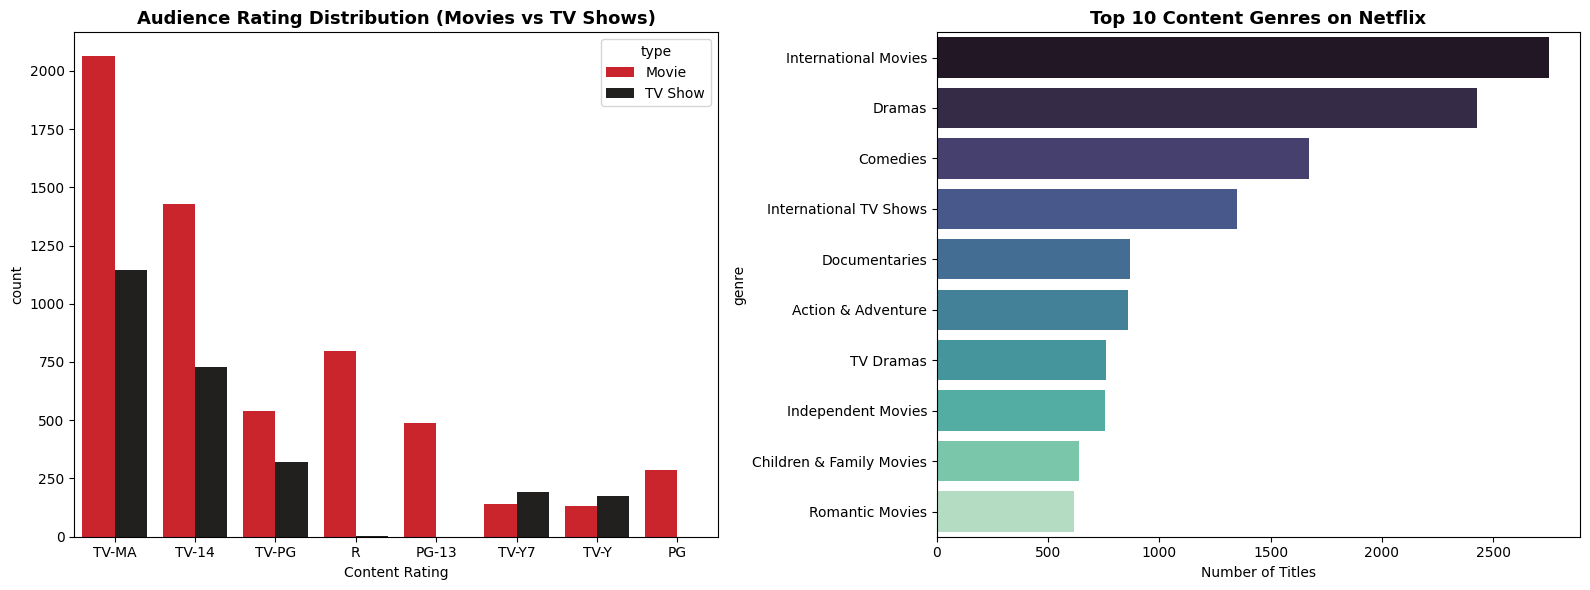

In [5]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.countplot(data=df_filtered_ratings, x='rating', hue='type', palette=['#E50914', '#221F1F'], order=top_ratings, ax=axes[0])
axes[0].set_title("Audience Rating Distribution (Movies vs TV Shows)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Content Rating")
sns.barplot(x=top_genres.values, y=top_genres.index, palette="mako", ax=axes[1])
axes[1].set_title("Top 10 Content Genres on Netflix", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Number of Titles")
plt.tight_layout()
plt.savefig("rating_and_genre_distribution.png", dpi=300)
print("Task 5 complete.")